# Шаг 6. Эксперимент: перемешаем пиксели. Заметит ли сеть?

Перемешаем пиксели **всех** картинок **одинаково** — как будто кто-то переставил провода от пикселей к входам сети.
Человек не узнает ни одной цифры: на месте «семёрки» будет белый шум. А сеть?

Подсказка к размышлению: первый слой `Linear` нашей сети соединён с **каждым** пикселем отдельным весом
и ничего не знает о том, какие пиксели **соседи**. Для неё порядок входов не важен.

> Нужна обученная сеть `mlp.pt` (ноутбук `03_train_mlp.ipynb`) — с ней сравним результат.
> Обучение новой сети займёт около минуты.

**Структура ноутбука (алгоритм):**
1. Импортируем PyTorch и помощники, создаём один случайный порядок 784 пикселей.
2. Описываем набор данных `Shuffled` — обёртку над MNIST, переставляющую пиксели каждой картинки.
3. Рисуем обычные и перемешанные цифры рядом, сохраняем в `shuffled.png`.
4. Обучаем **такую же** сеть `MLP` с нуля на перемешанных картинках.
5. Сравниваем точность обычной сети на обычных картинках и новой сети на перемешанных.

In [ ]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session01–session05 и dataset).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session03")  # здесь лежит common.py и сохраняются результаты
    sys.path.insert(0, os.getcwd())

    # Набор данных скачивается на Диск один раз, потом берётся готовый
    from torchvision import datasets

    datasets.MNIST(f"{COLAB_ROOT}/data", download=True)

## Общий модуль `common.py`

Во всех ноутбуках этой сессии используется модуль `common.py` из этой же папки:

| Имя | Что делает |
|-----|------------|
| `mnist(train)` | скачивает (один раз, ~12 МБ в папку `data`) и возвращает набор MNIST: обучающий (`train=True`, 60 000) или проверочный (`train=False`, 10 000) |
| `MLP` | многослойная сеть: 784 входа → 128 → 64 → 10 выходов |
| `train(model, dataset, epochs)` | цикл обучения из шага 3, без пояснений |
| `predict_all(model, dataset)` | ответы сети (номер цифры) для каждой картинки набора |
| `accuracy(model, dataset)` | доля картинок, на которых сеть ответила верно |
| `load_model()` | загрузить обученную сеть из `mlp.pt` (файл создаёт шаг 3) |
| `show()` | показать графики matplotlib и закрыть их |
| `MODEL_FILE` | путь к файлу `mlp.pt` |

> Ноутбуки нужно запускать из папки `session03`, иначе `import common` не найдёт модуль.
> Нужные библиотеки: `pip install -r requirements.txt`.

## 1. Импорт и случайный порядок пикселей

`torch.randperm(784)` — случайная перестановка чисел от 0 до 783. Например, `order[0] = 517` значит:
«на место пикселя 0 поставить пиксель 517». Перестановка создаётся **один раз** и применяется ко всем картинкам —
и к обучающим, и к проверочным. `manual_seed(0)` делает её одинаковой при каждом запуске.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset

from common import MLP, accuracy, load_model, mnist, show, train

torch.manual_seed(0)
order = torch.randperm(784)  # один и тот же новый порядок пикселей для всех картинок

## 2. Набор данных с перемешанными пикселями

Свой набор данных в PyTorch — это класс-наследник `Dataset` с двумя методами:
- `__len__` — сколько всего элементов (столько же, сколько в исходном MNIST);
- `__getitem__(i)` — вернуть `i`-й элемент `(картинка, метка)`.

Перестановка пикселей в `__getitem__`:
1. `image.view(-1)` — вытянуть картинку 1 × 28 × 28 в строку из 784 чисел;
2. `[order]` — **индексация списком**: взять пиксели в новом порядке;
3. `.view(1, 28, 28)` — сложить обратно в квадрат.

Метка не меняется. Исходный набор хранится в `self.base`, чтобы можно было сравнить с оригиналом.

In [6]:
class Shuffled(Dataset):
    """MNIST, в котором пиксели каждой картинки переставлены по order."""

    def __init__(self, base):
        self.base = base

    def __len__(self):
        return len(self.base)

    def __getitem__(self, i):
        image, label = self.base[i]
        return image.view(-1)[order].view(1, 28, 28), label


train_set, test_set = Shuffled(mnist(train=True)), Shuffled(mnist(train=False))

## 3. Как это выглядит

Верхний ряд — обычные цифры из проверочного набора (`test_set.base[i]`), нижний — те же картинки после перестановки (`test_set[i]`).
Подпись — правильный ответ.

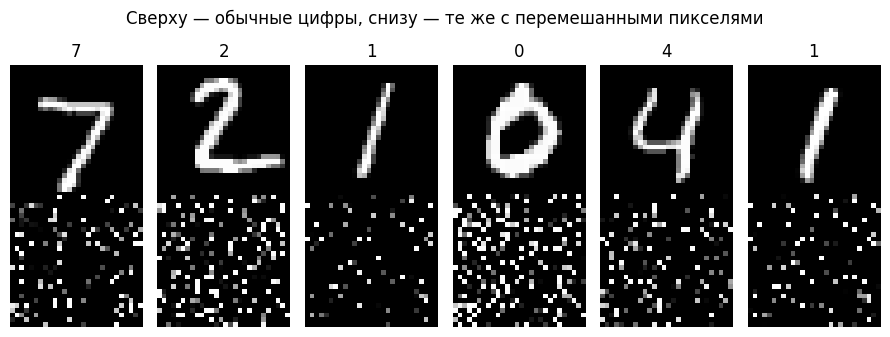

In [7]:
fig, axes = plt.subplots(2, 6, figsize=(9, 3.4))
for i in range(6):
    axes[0, i].imshow(test_set.base[i][0][0], cmap="gray")
    axes[1, i].imshow(test_set[i][0][0], cmap="gray")
    axes[0, i].set_title(test_set.base[i][1])
    axes[0, i].axis("off")
    axes[1, i].axis("off")
fig.suptitle("Сверху — обычные цифры, снизу — те же с перемешанными пикселями")
plt.tight_layout()
plt.savefig("shuffled.png", dpi=100)
show()

## 4. Обучаем такую же сеть на перемешанных картинках

Создаём новую сеть `MLP` (та же архитектура, случайные начальные веса) и обучаем её функцией `train` из `common.py` —
это тот же цикл, что в шаге 3: 3 эпохи, пачки по 64, оптимизатор Adam.

In [8]:
print("Обучаем такую же сеть на перемешанных картинках (около минуты)...")
model = MLP()
train(model, train_set, epochs=3)

Обучаем такую же сеть на перемешанных картинках (около минуты)...


## 5. Сравнение

- `normal` — точность сети из шага 3 (`load_model()`) на обычных проверочных картинках;
- `shuffled` — точность новой сети на перемешанных проверочных картинках.

Если числа почти одинаковые, значит, сети **всё равно**, где какой пиксель: она не использует то,
что соседние пиксели образуют линии и формы. Человеку же форма — главное.
Сети, которые учитывают соседство пикселей, — **свёрточные** — разберём в сессии 4.

In [5]:
normal = accuracy(load_model(), mnist(train=False))
shuffled = accuracy(model, test_set)
print(f"Обычные картинки:      {normal:.1%}")
print(f"Перемешанные пиксели:  {shuffled:.1%}")
print("\nВопрос: что это говорит о том, как сеть «видит» цифру?")
print("И что будет на фото кошек, где форма важнее отдельных пикселей?  → сессия 4")

Обычные картинки:      97.7%
Перемешанные пиксели:  97.4%

Вопрос: что это говорит о том, как сеть «видит» цифру?
И что будет на фото кошек, где форма важнее отдельных пикселей?  → сессия 4


## Попробуйте сами

1. Проверьте обычную сеть из `mlp.pt` на перемешанных картинках: `accuracy(load_model(), test_set)`. Почему так плохо?
2. А новую сеть — на обычных: `accuracy(model, mnist(train=False))`.
3. Перемешивайте пиксели каждой картинки **по-своему** (новый `randperm` внутри `__getitem__`). Сможет ли сеть научиться?
4. Сдвиньте все цифры на 3 пикселя вправо (`torch.roll(image, 3, dims=2)`) и проверьте обычную сеть. Что это говорит о её «зрении»?